# A4.1 · Does looking ahead improve training-image reconstruction and historical RankMe?

**Complete** · 20,736/20,736 committed decisions · 162/162 completed trajectories · 2026-11-25T16:53:11+01:00.

## Design and measurements

Each trajectory starts at the archived 8,000-arrival MAE checkpoint and carries its own encoder, decoder and AdamW state through 128 distinct BDD100K training captures. All starts receive the same fixed, seeded clip order and origins. Within-clip images follow the archived temporally sampled video frames. Base LRs are 0.0003, 0.001 and 0.003. There are three seeds. The 11 A3 actions and the original 128-image historical selection and independent audit banks are reused.

**Training-image loss.** At every arrival, measure absolute reconstruction loss on x0 before the decision and after the commitment on four identical audit masks, independent of the update and selector masks. Record both losses even when the controller skips. Also record pre/post loss on the exact mask used for the training step. The learned-only online curves average origins where an update was committed. The skipped-only series uses the other origins. Neither curve alone controls the mixture of image difficulties.

**Fixed training-image cohort.** At step zero and every 16 decisions, evaluate all 128 origin images with four fixed masks. Once decisions are known, recompute a curve on precisely the same subset of origins that this trajectory chose to train on. Also retain the full 128-image cohort and, for the paired lookahead contrast, the set selected in both runs. These retrospective readouts never enter the decision. RankMe is measured on the independent historical bank at step zero and after every commitment.

**Policy grid.** P1 always takes the tied 1× update and P2 the decoder-only 1× update. These ignore the horizon, so each runs once per LR and seed. P3 maximizes reconstruction with a 0.1-RMS RankMe guard. P4 prioritizes meaningful rank gain with no loss decline. P5/A4 takes P4's choice when feasible, otherwise it maximizes meaningful loss improvement with zero rank decline. P6 uses that last rule alone. Each adaptive policy runs four genuinely independent trajectories at H=0, 1, 4 and 16. **P5 H=0 is the no-lookahead A4 control.** It sees x0 only. H>0 uses the mean over x1 through xH. Future frames are inference-only.

To isolate lookahead, all horizons and LRs use the same A3 reference thresholds within seed: 0.1 times the H16 loss or N128 rank RMS. This fixes numerical decision thresholds across ablations. Masks, checkpoints, bank IDs and update opportunities are paired. Inference batch geometry is identical across horizons, with repeated eligible images padding unused slots. Each image is processed independently and padding is excluded from scores.

**Scope of uncertainty.** Compare policies within LR and seed. Intervals are across three paired seeds and conditional on one fixed stream of captures. Changing the selected subset changes the difficulty distribution. The all-origin cohort is shared by every policy.

In [ ]:
import base64, gzip, hashlib, json
from pathlib import Path
from IPython.display import display, Markdown

name = "MAE_A41_Training_Image_Lookahead.ipynb"
locations = (Path.cwd() / name, *(root / "project/cafl4ds/notebooks/selected/mae" / name
             for root in (Path.cwd(), *Path.cwd().parents)))
notebook = next((p for p in locations if p.is_file()), None)
if notebook is None:
    raise FileNotFoundError(f"Run this cell from the notebook folder or set notebook to the path of {name}.")
data = json.loads(notebook.read_text(encoding="utf-8"))["metadata"]["a41_snapshot"]
archive = base64.b64decode(data["gzip_base64"], validate=True)
assert hashlib.sha256(archive).hexdigest() == data["sha256"]
snapshot = json.loads(gzip.decompress(archive))
spec, traces = snapshot["design"], snapshot["traces"]

In [ ]:
"""CPU-only A4.1 trajectory and paired lookahead analysis."""
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import t as student_t

def average(x):
    x=np.asarray(x,dtype=float)
    return float(x[np.isfinite(x)].mean()) if np.isfinite(x).any() else np.nan

def interval(x):
    v=np.asarray(x,dtype=float); v=v[np.isfinite(v)]
    if len(v)==0:return "—"
    if len(v)==1:return f"{v[0]:+.5f} (1 seed)"
    width=student_t.ppf(.975,len(v)-1)*v.std(ddof=1)/np.sqrt(len(v))
    return f"{v.mean():+.5f} [{v.mean()-width:+.5f}, {v.mean()+width:+.5f}]"

def verify(spec,traces):
    keys=set()
    for tr in traces:
        key=(tr["seed"],tr["lr"],tr["policy"],tr["h"])
        assert key not in keys;keys.add(key)
        prior=tr["initial_rank"]
        for i,row in enumerate(tr["steps"]):
            k=tr["policy"]; act=row["action"]
            assert i==row["i"] and len(row["pre"])==len(row["post"])==spec["audit_repeats"]
            if k in ("P1","P2"):
                assert act==(7 if k=="P1" else 2)
            else:
                raw=np.array(row["candidates"]);assert raw.shape==(11,2)
                sc=spec["scales"][str(tr["seed"])]
                l=(raw[0,0]-raw[:,0])/sc["loss"][-1];r=(raw[:,1]-raw[0,1])/sc["rank"][1]
                def best(score,guard,secondary):
                    eligible=np.flatnonzero(guard & (score>spec["min_gain"]))
                    return int(max(eligible,key=lambda j:(score[j],secondary[j],-j))) if len(eligible) else 0
                chosen=best(r,l>=0,l) if k in ("P4","P5") else 0
                stage="rank" if chosen else "skip"
                if not chosen and k!="P4":
                    chosen=best(l,r>=(-spec["rank_guard"] if k=="P3" else 0),r)
                    stage="loss" if chosen else "skip"
                assert chosen==act and row["mode"]==stage
            if spec["actions"][act]["encoder"]==0:assert row["rank"]==prior
            if act==0:assert row["pre"]==row["post"] and row["training_mask_pre"]==row["training_mask_post"]
            prior=row["rank"]
        assert set(map(int,tr["cohorts"]))==set(range(0,len(tr["steps"])+1,spec["interval"]))
        assert all(len(v)==len(spec["clips"]) for v in tr["cohorts"].values())
    return sum(len(t["steps"]) for t in traces)

def series(spec,tr):
    s=tr["steps"]; act=np.array([r["action"] for r in s]); train=act!=0
    pre=np.array([np.mean(r["pre"]) for r in s]);post=np.array([np.mean(r["post"]) for r in s])
    return dict(pre=pre,post=post,train=train,encoder=np.array([spec["actions"][j]["encoder"]>0 for j in act]),
                rank=np.r_[tr["initial_rank"],[r["rank"] for r in s]])

def fmt(x):
    return f"{x:.5f}" if np.isfinite(x) else "—"

def summaries(spec,traces):
    groups={}
    for tr in traces:
        if len(tr["steps"])!=len(spec["clips"]):continue
        s=series(spec,tr);train=s["train"];pre=s["pre"];post=s["post"];rank=s["rank"]
        delta=np.array(tr["cohorts"][str(len(train))])-tr["cohorts"]["0"]
        metrics=[(~train).mean(),s["encoder"].mean(),average(pre[train]),average(post[train]),average(pre[~train]),
                 average(delta[train]),average(delta),rank[-1]-rank[0]]
        groups.setdefault((tr["lr"],tr["policy"],tr["h"]),[]).append(metrics)
    lines=["### Completed trajectories","",
           "Learned pre/post and skipped pre are absolute x0 losses using four held-fixed audit masks. Cohort Δ is final minus initial loss on exactly the same images. Each seed receives equal weight. Dashes indicate an empty selected or skipped group.","",
           "| Base LR | Policy | H | Seeds | Skip | Encoder updates | Learned pre | Learned post | Skipped pre | Learned cohort Δ | All x0 Δ | Audit RankMe Δ |",
           "|---:|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|"]
    for (lr,p,h),rows in sorted(groups.items(),key=lambda e:(e[0][0],e[0][1],e[0][2] or 0)):
        v=[average(col) for col in np.array(rows).T]
        lines.append(f"| {lr:g} | {p} | {h if h is not None else 'fixed'} | {len(rows)} | {v[0]:.1%} | {v[1]:.1%} | "+" | ".join(fmt(x) for x in v[2:])+" |")
    if not groups:lines.append("\nAwaiting the first full 128-decision trajectory.")
    return "\n".join(lines)

def paired(spec,traces):
    size=len(spec["clips"])
    runs={(r["lr"],r["h"],r["seed"]):r for r in traces if r["policy"]=="P5" and len(r["steps"])==size}
    lines=["### Does future lookahead improve on x0-only A4?","",
           "Each row compares independent P5 trajectories, H minus H=0, pairing the same LR and seed. Loss differences below zero favor future lookahead. RankMe differences above zero favor future lookahead. The common learned set contains only x0s selected for updates by both controllers. It is a post-selection diagnostic; the all-x0 endpoint uses every origin. Reported intervals are paired 95% Student t intervals across seeds on this fixed clip stream.","",
           "| LR | H vs 0 | Paired seeds | Common learned x0s (mean) | Final all-x0 loss difference | Final common-learned loss difference | Final audit RankMe difference |",
           "|---:|---:|---:|---:|---:|---:|---:|"]
    for lr in spec["lrs"]:
        for h in (1,4,16):
            pairs=[(runs[(lr,h,s)],runs[(lr,0,s)]) for s in spec["seeds"] if (lr,h,s) in runs and (lr,0,s) in runs]
            if not pairs:continue
            vals=[]
            for a,b in pairs:
                d=np.array(a["cohorts"][str(size)])-b["cohorts"][str(size)]
                both=series(spec,a)["train"] & series(spec,b)["train"]
                vals.append([both.sum(),d.mean(),average(d[both]),a["steps"][-1]["rank"]-b["steps"][-1]["rank"]])
            common,all_loss,learned,rank=np.array(vals).T
            lines.append(f"| {lr:g} | {h} | {len(pairs)} | {common.mean():.1f} | {interval(all_loss)} | {interval(learned)} | {interval(rank)} |")
    if len(lines)==5:lines.append("\nMatched results appear once both trajectories finish.")
    return "\n".join(lines)

def plot(spec,traces,lr=.003,policy="P5"):
    eligible=[r for r in traces if r["policy"]==policy and r["lr"]==lr and r["steps"]]
    if not eligible:return None
    fig,axs=plt.subplots(2,2,figsize=(12,7.2),layout="constrained")
    for h,color in zip(([None] if policy in ("P1","P2") else spec["horizons"]),["#475780","#A05930","#A88C1C","#06786C"]):
        runs=[r for r in eligible if r["h"]==h]
        if not runs:continue
        # Matched length at all plotted positions, including the current in-progress snapshot.
        length=min(len(r["steps"]) for r in runs); label=f"{'Fixed' if h is None else 'H='+str(h)} · {len(runs)} seed(s)"
        ss=[series(spec,r) for r in runs]
        rank=np.mean([s["rank"][:length+1] for s in ss],axis=0)
        axs[0,1].plot(range(length+1),rank,color=color,label=label)
        for selected,style in [(True,"-"),(False,":")]:
            xx=[];yy=[];zz=[]
            for begin in range(0,length,16):
                stop=min(begin+16,length);sl=slice(begin,stop)
                pre=[average(s["pre"][sl][s["train"][sl]==selected]) for s in ss]
                post=[average(s["post"][sl][s["train"][sl]==selected]) for s in ss]
                xx.append((begin+stop+1)/2);yy.append(average(pre));zz.append(average(post))
            if selected:
                axs[0,0].plot(xx,yy,color=color,ls="--",marker=".",alpha=.8)
                axs[0,0].plot(xx,zz,color=color,ls=style,marker="o",ms=3,label=label)
            else:axs[1,1].plot(xx,yy,color=color,marker=".",label=label)
        xx=list(range(0,length+1,spec["interval"]));ys=[]
        for k in xx:
            ys.append(average([average(np.array(r["cohorts"][str(k)])[:length][s["train"][:length]]) for r,s in zip(runs,ss)]))
        axs[1,0].plot(xx,ys,color=color,marker="o",ms=3,label=label)
    for ax,title in zip(axs.flat,["Learned x0 · pre (dashed) and post (solid)","Independent historical audit RankMe",
                                 "Identical learned-x0 cohort at each checkpoint","Skipped x0 · loss on arrival"]):
        ax.set(title=title,xlabel="Decision number");ax.grid(axis="y",alpha=.2)
        ax.spines[["top","right"]].set_visible(False)
    axs[0,1].legend(fontsize=8,frameon=False)
    fig.suptitle(f"{policy} · base LR {lr:g} · reconstruction measured on origin images")
    return fig

print(f'Verified {verify(spec,traces):,} committed decisions.')

## Training-image trajectories

Solid and dashed lines in the learned-image panel show post- and pre-update losses. Time-varying quantities are grouped in 16-decision windows. Early snapshots use the learned subset available so far. Edit the LR and policy in any plot cell to inspect a different trajectory family.

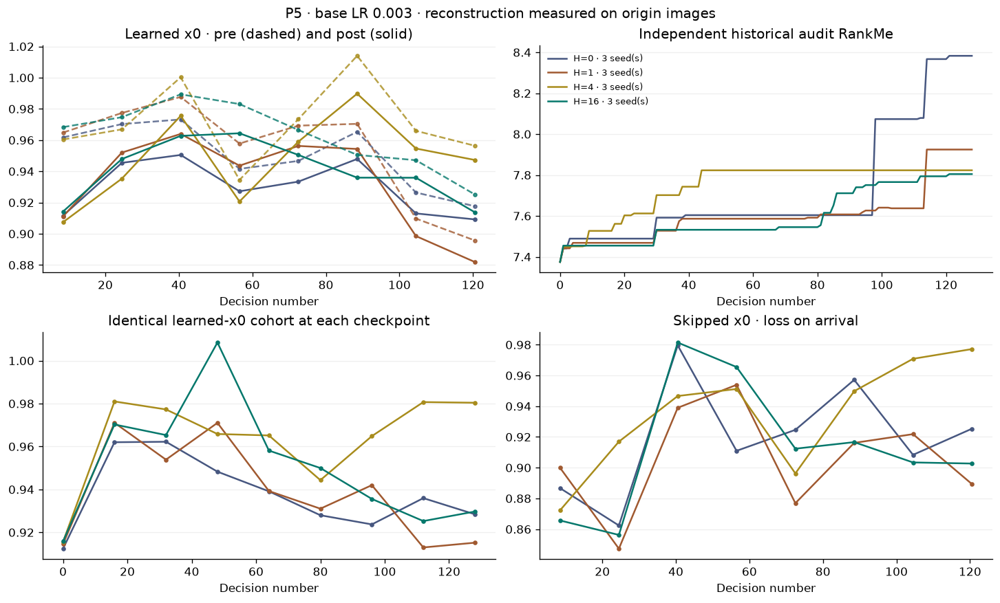

In [ ]:
fig=plot(spec,traces,lr=0.003,policy="P5")
if fig is not None: plt.show()

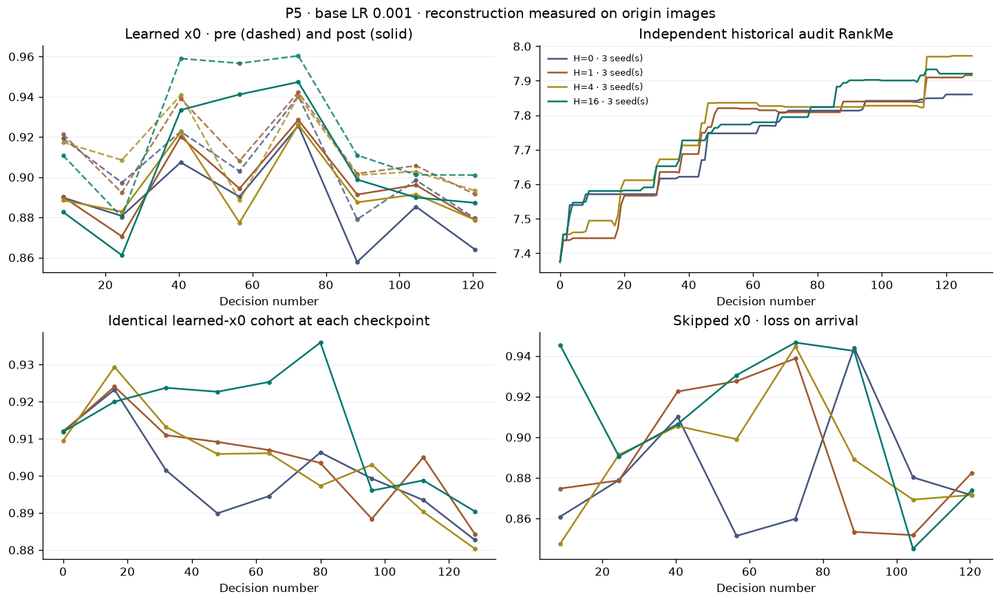

In [ ]:
fig=plot(spec,traces,lr=0.001,policy="P5")
if fig is not None: plt.show()

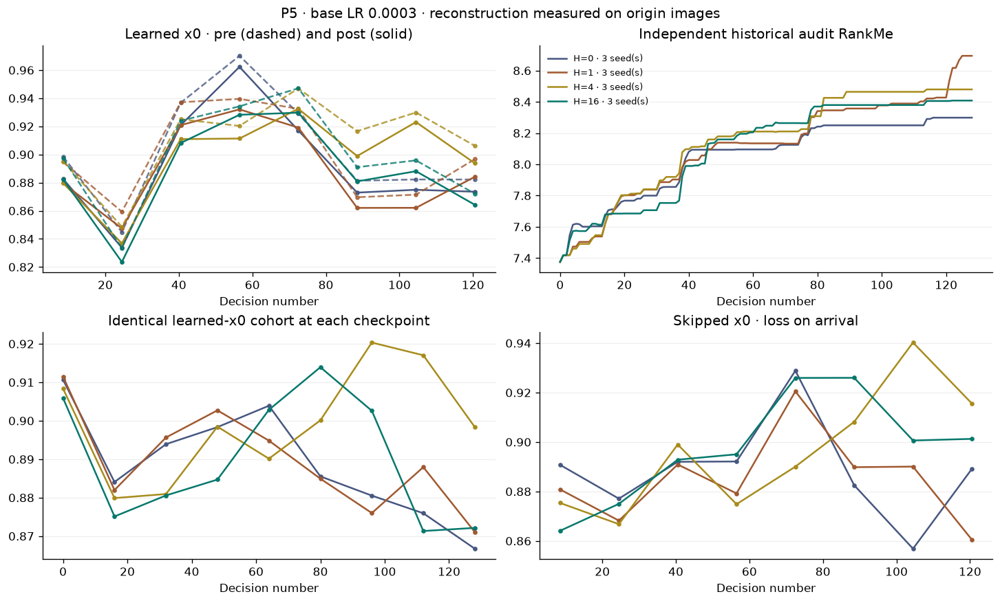

In [ ]:
fig=plot(spec,traces,lr=0.0003,policy="P5")
if fig is not None: plt.show()

In [ ]:
display(Markdown(paired(spec,traces)))

### Does future lookahead improve on x0-only A4?

Each row compares independent P5 trajectories, H minus H=0, pairing the same LR and seed. Loss differences below zero favor future lookahead. RankMe differences above zero favor future lookahead. The common learned set contains only x0s selected for updates by both controllers. It is a post-selection diagnostic; the all-x0 endpoint uses every origin. Reported intervals are paired 95% Student t intervals across seeds on this fixed clip stream.

| LR | H vs 0 | Paired seeds | Common learned x0s (mean) | Final all-x0 loss difference | Final common-learned loss difference | Final audit RankMe difference |
|---:|---:|---:|---:|---:|---:|---:|
| 0.0003 | 1 | 3 | 59.3 | +0.00152 [-0.02191, +0.02494] | +0.00476 [-0.00966, +0.01917] | +0.39587 [-1.51892, +2.31066] |
| 0.0003 | 4 | 3 | 48.0 | +0.03393 [-0.02260, +0.09046] | +0.02995 [-0.01109, +0.07099] | +0.18084 [-0.48146, +0.84314] |
| 0.0003 | 16 | 3 | 55.7 | +0.01177 [-0.06763, +0.09118] | +0.00921 [-0.07690, +0.09532] | +0.10959 [-0.41850, +0.63767] |
| 0.001 | 1 | 3 | 78.0 | -0.00382 [-0.02223, +0.01459] | -0.00462 [-0.01771, +0.00847] | +0.05585 [-0.78535, +0.89704] |
| 0.001 | 4 | 3 | 78.7 | -0.00225 [-0.01471, +0.01021] | -0.00309 [-0.03016, +0.02397] | +0.11195 [-1.13192, +1.35582] |
| 0.001 | 16 | 3 | 69.3 | +0.00168 [-0.03259, +0.03596] | +0.00661 [-0.02703, +0.04024] | +0.06019 [-1.48489, +1.60527] |
| 0.003 | 1 | 3 | 74.3 | -0.02333 [-0.24678, +0.20012] | -0.01455 [-0.17897, +0.14987] | -0.45826 [-1.98460, +1.06809] |
| 0.003 | 4 | 3 | 66.7 | +0.05375 [-0.17507, +0.28258] | +0.04603 [-0.14349, +0.23556] | -0.55967 [-2.17493, +1.05560] |
| 0.003 | 16 | 3 | 65.7 | -0.01058 [-0.28198, +0.26083] | -0.00506 [-0.20758, +0.19746] | -0.57831 [-2.72963, +1.57302] |

In [ ]:
display(Markdown(summaries(spec,traces)))

### Completed trajectories

Learned pre/post and skipped pre are absolute x0 losses using four held-fixed audit masks. Cohort Δ is final minus initial loss on exactly the same images. Each seed receives equal weight. Dashes indicate an empty selected or skipped group.

| Base LR | Policy | H | Seeds | Skip | Encoder updates | Learned pre | Learned post | Skipped pre | Learned cohort Δ | All x0 Δ | Audit RankMe Δ |
|---:|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 0.0003 | P1 | fixed | 3 | 0.0% | 100.0% | 0.86950 | 0.86336 | — | -0.06299 | -0.06299 | -1.46528 |
| 0.0003 | P2 | fixed | 3 | 0.0% | 0.0% | 0.86727 | 0.86350 | — | -0.06474 | -0.06474 | 0.00000 |
| 0.0003 | P3 | 0 | 3 | 34.4% | 22.1% | 0.89592 | 0.88427 | 0.88374 | -0.03446 | -0.03387 | -0.57121 |
| 0.0003 | P3 | 1 | 3 | 30.5% | 28.6% | 0.88845 | 0.87733 | 0.87791 | -0.04501 | -0.04453 | -0.73265 |
| 0.0003 | P3 | 4 | 3 | 36.5% | 21.4% | 0.89771 | 0.88561 | 0.88731 | -0.03494 | -0.03202 | -0.48549 |
| 0.0003 | P3 | 16 | 3 | 43.5% | 18.5% | 0.90079 | 0.88810 | 0.89848 | -0.01894 | -0.02000 | -0.32999 |
| 0.0003 | P4 | 0 | 3 | 96.1% | 3.9% | 0.89180 | 0.85940 | 0.94690 | -0.04113 | 0.03882 | 0.75937 |
| 0.0003 | P4 | 1 | 3 | 94.8% | 5.2% | 0.90073 | 0.86883 | 0.93074 | -0.04259 | 0.00816 | 1.03456 |
| 0.0003 | P4 | 4 | 3 | 94.8% | 5.2% | 0.88594 | 0.85657 | 0.94064 | 0.02384 | 0.07365 | 1.11504 |
| 0.0003 | P4 | 16 | 3 | 95.8% | 4.2% | 0.88684 | 0.85856 | 0.92416 | -0.06131 | 0.00756 | 0.84502 |
| 0.0003 | P5 | 0 | 3 | 38.5% | 12.0% | 0.89724 | 0.88607 | 0.88714 | -0.04395 | -0.04299 | 0.92365 |
| 0.0003 | P5 | 1 | 3 | 37.5% | 14.8% | 0.89663 | 0.88488 | 0.88576 | -0.04045 | -0.04148 | 1.31952 |
| 0.0003 | P5 | 4 | 3 | 46.6% | 12.0% | 0.90761 | 0.89503 | 0.90151 | -0.01000 | -0.00906 | 1.10449 |
| 0.0003 | P5 | 16 | 3 | 38.8% | 13.3% | 0.89570 | 0.88427 | 0.90464 | -0.03375 | -0.03122 | 1.03324 |
| 0.0003 | P6 | 0 | 3 | 38.5% | 12.0% | 0.89724 | 0.88607 | 0.88714 | -0.04395 | -0.04299 | 0.92365 |
| 0.0003 | P6 | 1 | 3 | 39.8% | 15.4% | 0.90451 | 0.89313 | 0.88856 | -0.02929 | -0.02604 | 1.16878 |
| 0.0003 | P6 | 4 | 3 | 45.6% | 12.2% | 0.90383 | 0.89160 | 0.89712 | -0.01302 | -0.00615 | 0.85437 |
| 0.0003 | P6 | 16 | 3 | 40.9% | 12.5% | 0.90032 | 0.88842 | 0.89001 | -0.02704 | -0.02551 | 1.03081 |
| 0.001 | P1 | fixed | 3 | 0.0% | 100.0% | 0.88981 | 0.87769 | — | -0.03980 | -0.03980 | -2.97825 |
| 0.001 | P2 | fixed | 3 | 0.0% | 0.0% | 0.87400 | 0.86517 | — | -0.05444 | -0.05444 | 0.00000 |
| 0.001 | P3 | 0 | 3 | 26.3% | 10.7% | 0.90793 | 0.89059 | 0.89237 | -0.02862 | -0.03062 | -0.47592 |
| 0.001 | P3 | 1 | 3 | 32.6% | 8.1% | 0.92189 | 0.90156 | 0.91348 | -0.00137 | -0.00805 | -0.05063 |
| 0.001 | P3 | 4 | 3 | 35.4% | 8.9% | 0.92479 | 0.90485 | 0.90898 | 0.00051 | -0.00651 | -0.32810 |
| 0.001 | P3 | 16 | 3 | 32.3% | 10.7% | 0.91125 | 0.89308 | 0.90796 | -0.02563 | -0.03223 | -0.61934 |
| 0.001 | P4 | 0 | 3 | 96.9% | 3.1% | 0.86592 | 0.82753 | 0.97175 | -0.02724 | 0.07287 | 1.00146 |
| 0.001 | P4 | 1 | 3 | 96.9% | 3.1% | 0.89277 | 0.83938 | 0.97672 | -0.02068 | 0.07845 | 0.96253 |
| 0.001 | P4 | 4 | 3 | 96.9% | 3.1% | 0.88787 | 0.82327 | 0.96945 | -0.02260 | 0.05214 | 0.92573 |
| 0.001 | P4 | 16 | 3 | 96.4% | 3.6% | 0.91120 | 0.84872 | 0.97059 | -0.00905 | 0.05450 | 1.02896 |
| 0.001 | P5 | 0 | 3 | 24.5% | 4.9% | 0.90742 | 0.89024 | 0.88649 | -0.02931 | -0.03083 | 0.48548 |
| 0.001 | P5 | 1 | 3 | 25.8% | 7.0% | 0.91318 | 0.89646 | 0.89321 | -0.02749 | -0.03465 | 0.54132 |
| 0.001 | P5 | 4 | 3 | 29.4% | 6.2% | 0.91303 | 0.89553 | 0.89807 | -0.02909 | -0.03308 | 0.59743 |
| 0.001 | P5 | 16 | 3 | 32.6% | 7.8% | 0.91661 | 0.89937 | 0.90598 | -0.02144 | -0.02914 | 0.54567 |
| 0.001 | P6 | 0 | 3 | 29.9% | 4.2% | 0.91607 | 0.89821 | 0.88820 | -0.03147 | -0.03617 | 0.21935 |
| 0.001 | P6 | 1 | 3 | 27.6% | 5.7% | 0.91291 | 0.89562 | 0.88547 | -0.01966 | -0.02711 | 0.41270 |
| 0.001 | P6 | 4 | 3 | 34.9% | 5.2% | 0.92132 | 0.90337 | 0.91176 | 0.00523 | -0.00445 | 0.55758 |
| 0.001 | P6 | 16 | 3 | 34.1% | 7.0% | 0.91733 | 0.89956 | 0.91375 | -0.02179 | -0.03073 | 0.41932 |
| 0.003 | P1 | fixed | 3 | 0.0% | 100.0% | 0.92188 | 0.90641 | — | -0.02446 | -0.02446 | -4.35387 |
| 0.003 | P2 | fixed | 3 | 0.0% | 0.0% | 0.90615 | 0.89108 | — | -0.04187 | -0.04187 | 0.00000 |
| 0.003 | P3 | 0 | 3 | 21.9% | 5.7% | 0.94704 | 0.92492 | 0.91441 | 0.00128 | -0.00070 | 0.54635 |
| 0.003 | P3 | 1 | 3 | 32.6% | 4.9% | 0.96076 | 0.93557 | 0.94365 | 0.03262 | 0.03574 | -0.29870 |
| 0.003 | P3 | 4 | 3 | 35.9% | 6.2% | 0.96360 | 0.93755 | 0.95163 | 0.03979 | 0.03914 | -0.19510 |
| 0.003 | P3 | 16 | 3 | 37.0% | 5.2% | 0.96606 | 0.94111 | 0.95719 | 0.01739 | 0.01641 | 0.05229 |
| 0.003 | P4 | 0 | 3 | 97.1% | 2.9% | 0.86234 | 0.79812 | 0.94358 | -0.05210 | 0.02986 | 0.79545 |
| 0.003 | P4 | 1 | 3 | 96.4% | 3.6% | 0.87708 | 0.80203 | 0.95244 | -0.01727 | 0.06176 | 0.95793 |
| 0.003 | P4 | 4 | 3 | 96.6% | 3.4% | 0.87079 | 0.79720 | 0.97878 | -0.00059 | 0.09082 | 0.90696 |
| 0.003 | P4 | 16 | 3 | 97.7% | 2.3% | 0.91298 | 0.83385 | 0.93350 | -0.02142 | 0.02272 | 0.81790 |
| 0.003 | P5 | 0 | 3 | 28.9% | 2.1% | 0.94846 | 0.92612 | 0.93321 | 0.01604 | 0.01965 | 1.00805 |
| 0.003 | P5 | 1 | 3 | 24.5% | 3.1% | 0.95305 | 0.93104 | 0.91674 | 0.00064 | -0.00368 | 0.54979 |
| 0.003 | P5 | 4 | 3 | 39.1% | 3.1% | 0.96443 | 0.93850 | 0.95914 | 0.06483 | 0.07341 | 0.44838 |
| 0.003 | P5 | 16 | 3 | 32.3% | 3.6% | 0.95968 | 0.93600 | 0.93581 | 0.01388 | 0.00908 | 0.42974 |
| 0.003 | P6 | 0 | 3 | 31.8% | 0.8% | 0.95711 | 0.93265 | 0.94285 | 0.02524 | 0.02412 | 0.44579 |
| 0.003 | P6 | 1 | 3 | 26.6% | 1.0% | 0.94766 | 0.92621 | 0.92590 | 0.01095 | 0.01200 | 0.11140 |
| 0.003 | P6 | 4 | 3 | 24.0% | 3.4% | 0.95070 | 0.92805 | 0.92036 | -0.01995 | -0.02356 | 0.20767 |
| 0.003 | P6 | 16 | 3 | 26.0% | 3.9% | 0.95704 | 0.93373 | 0.92768 | -0.00301 | -0.00996 | 0.31743 |

## Inspect an individual decision

Run All with NumPy, SciPy, Matplotlib and IPython to verify every selector choice from its measured candidate scores and recalculate the plots and tables offline. The embedded snapshot contains the protocol, receipts, individual audit loss draws, cohort measurements and worker source. Original images, CUDA environment and checkpoints are required only for retraining.

In [ ]:
if traces and traces[0]["steps"]:
    trace=traces[0]; i=0
    display(spec["clips"][i], trace["steps"][i])
print(list(snapshot["source"]))